In [5]:
import os
import json
import random
import numpy as np
from collections import Counter

import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader


#### Seed Everything

In [6]:
def seed_everything(seed=42):
    # 1. Base Python environment seeds
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    
    # 2. PyTorch CPU and GPU seeds
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # Safe for multi-GPU setups
    
    # 3. Configure CUDA reproducibility settings
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    
    # 4. Force strict deterministic operations within PyTorch (Throws warnings/errors if non-reproducible functions are used)
    torch.use_deterministic_algorithms(True, warn_only=True)
    
    print(f"✅ Environment successfully seeded with seed: {seed}")

### Sample Data 

train info: 

Classes: ['NORMAL', 'PNEUMONIA']
Class NORMAL size: 1341
Sample Image:


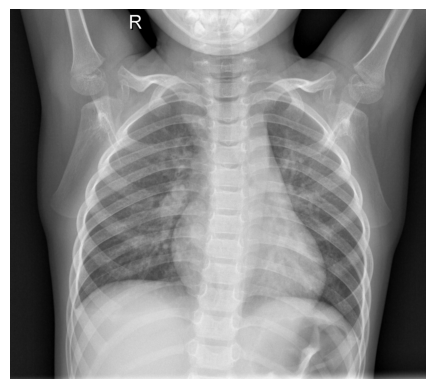

Class PNEUMONIA size: 3875
Sample Image:


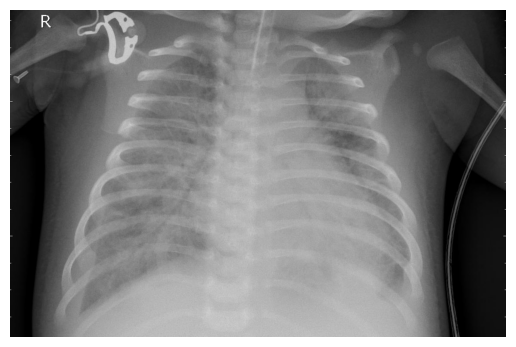

test info: 

Classes: ['NORMAL', 'PNEUMONIA']
Class NORMAL size: 234
Sample Image:


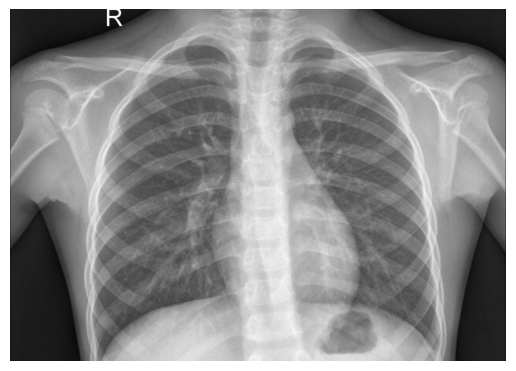

Class PNEUMONIA size: 390
Sample Image:


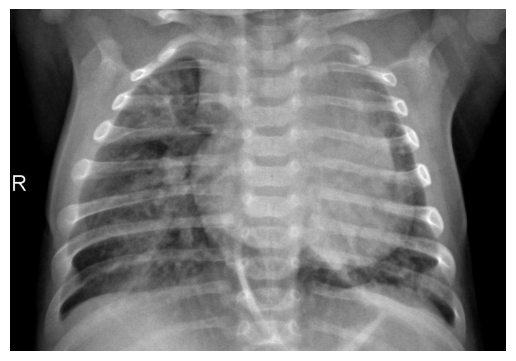

val info: 

Classes: ['NORMAL', 'PNEUMONIA']
Class NORMAL size: 8
Sample Image:


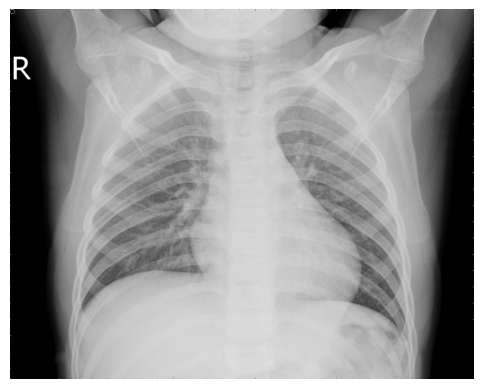

Class PNEUMONIA size: 8
Sample Image:


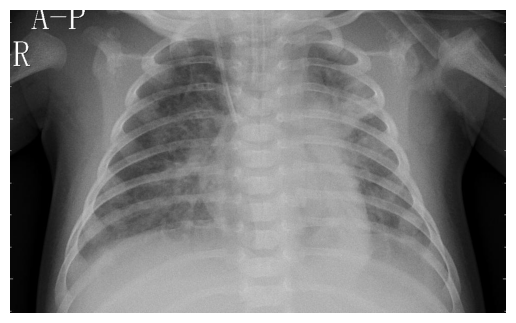

In [3]:
def imshow(image):
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

def explore_dataset(dataroot):

    splits = ['train', 'test', 'val']
    for split in splits:
        print(f'{split} info: \n')
        classes = [c for c in os.listdir(os.path.join(dataroot, split)) if os.path.isdir(os.path.join(dataroot, split, c))]
        print(f'Classes: {classes}')
        for cls in classes:
            class_path = os.path.join(dataroot, split, cls)
            class_size = len([f for f in os.listdir(class_path) if os.path.join(class_path, f).endswith(('.png', '.jpg', '.jpeg'))])
            print(f'Class {cls} size: {class_size}')
            print('Sample Image:')
            imshow(cv2.imread(os.path.join(class_path, os.listdir(class_path)[0])))


explore_dataset('C:\\Users\\mahes\\Desktop\\datasets\\chestxray')

#### NOW define datasets with ImageFolder

In [7]:

train_path = 'C:\\Users\\mahes\\Desktop\\datasets\\chestxray\\train'
test_path = 'C:\\Users\\mahes\\Desktop\\datasets\\chestxray\\test'
val_path = 'C:\\Users\\mahes\\Desktop\\datasets\\chestxray\\val'


seed_everything(42)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

✅ Environment successfully seeded with seed: 42


In [8]:
seed_everything(42)
train_original = datasets.ImageFolder(train_path, transform=transform)
test_dataset = datasets.ImageFolder(test_path, transform=transform)
val_original = datasets.ImageFolder(val_path, transform=transform)

print(f'Train counts: \nsize: {len(train_original)} \nclasses: {train_original.classes} \n class sizes: {Counter(train_original.targets)}')
print(f'Test counts: \nsize: {len(test_dataset)} \nclasses: {test_dataset.classes} \n class sizes: {Counter(test_dataset.targets)}')    
print(f'Val counts: \nsize: {len(val_original)} \nclasses: {val_original.classes} \n class sizes: {Counter(val_original.targets)}')


✅ Environment successfully seeded with seed: 42
Train counts: 
size: 5216 
classes: ['NORMAL', 'PNEUMONIA'] 
 class sizes: Counter({1: 3875, 0: 1341})
Test counts: 
size: 624 
classes: ['NORMAL', 'PNEUMONIA'] 
 class sizes: Counter({1: 390, 0: 234})
Val counts: 
size: 16 
classes: ['NORMAL', 'PNEUMONIA'] 
 class sizes: Counter({0: 8, 1: 8})


#### Stratify Train to get more Val images

In [9]:

seed_everything(42)
train_part, val_part = train_test_split(range(len(train_original.targets)), test_size=0.2, random_state=42, stratify=train_original.targets)
print(f'Train part: {len(train_part)}, Val part: {len(val_part)}')
print(f'Train part class distribution: {Counter([train_original.targets[i] for i in train_part])}')
print(f'Val part class distribution: {Counter([train_original.targets[i] for i in val_part])}')

train_val_indices = {'train_indices': train_part, 'val_indices': val_part}
with open('train_val_indices.json', 'w') as f:
    json.dump(train_val_indices, f)
print('Train and validation indices saved to train_val_indices.json')

with open('train_val_indices.json', 'r') as f:
    loaded_indices = json.load(f)
print(f'Loaded train indices: {len(loaded_indices["train_indices"])}, Loaded val indices: {len(loaded_indices["val_indices"])}')
print(f'Loaded train class distribution: {Counter([train_original.targets[i] for i in loaded_indices["train_indices"]])}')
print(f'Loaded val class distribution: {Counter([train_original.targets[i] for i in loaded_indices["val_indices"]])}')


✅ Environment successfully seeded with seed: 42
Train part: 4172, Val part: 1044
Train part class distribution: Counter({1: 3099, 0: 1073})
Val part class distribution: Counter({1: 776, 0: 268})
Train and validation indices saved to train_val_indices.json
Loaded train indices: 4172, Loaded val indices: 1044
Loaded train class distribution: Counter({1: 3099, 0: 1073})
Loaded val class distribution: Counter({1: 776, 0: 268})


In [10]:
set(train_part) & set(val_part)

set()

#### Now, consolidate all datasets

In [11]:

seed_everything(42)
train_dataset = torch.utils.data.Subset(train_original, loaded_indices['train_indices'])

val_subset = torch.utils.data.Subset(train_original, loaded_indices['val_indices'])
val_dataset = torch.utils.data.ConcatDataset([val_original, val_subset])

print(f'Train dataset info:\nLength: {len(train_dataset)}\nclasses: {train_dataset.dataset.classes}\nclass sizes: {Counter([train_dataset.dataset.targets[i] for i in train_dataset.indices])}')
print(f'Val dataset info:\nLength: {len(val_dataset)}\nclasses: {val_original.classes}\nclass sizes: {Counter(val_original.targets) + Counter([val_dataset.datasets[1].dataset.targets[i] for i in val_dataset.datasets[1].indices])}')

print(f'Train dataset class distribution: {Counter([train_dataset.dataset.targets[i] for i in train_dataset.indices])}')
print(f'Val dataset class distribution: {Counter(val_original.targets) + Counter([val_dataset.datasets[1].dataset.targets[i] for i in val_dataset.datasets[1].indices])}')

print(f'Test dataset info:\nLength: {len(test_dataset)}\nclasses: {test_dataset.classes}\nclass sizes: {Counter(test_dataset.targets)}')
print(f'Test dataset class distribution: {Counter(test_dataset.targets)}')

✅ Environment successfully seeded with seed: 42
Train dataset info:
Length: 4172
classes: ['NORMAL', 'PNEUMONIA']
class sizes: Counter({1: 3099, 0: 1073})
Val dataset info:
Length: 1060
classes: ['NORMAL', 'PNEUMONIA']
class sizes: Counter({1: 784, 0: 276})
Train dataset class distribution: Counter({1: 3099, 0: 1073})
Val dataset class distribution: Counter({1: 784, 0: 276})
Test dataset info:
Length: 624
classes: ['NORMAL', 'PNEUMONIA']
class sizes: Counter({1: 390, 0: 234})
Test dataset class distribution: Counter({1: 390, 0: 234})


#### DataLoaders

In [13]:

seed_everything(42)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)

✅ Environment successfully seeded with seed: 42


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.535425].


Images dtypes: torch.float32, Images shape: torch.Size([32, 3, 224, 224])
Labels dtypes: torch.int64, Labels shape: torch.Size([32])
Batch size: 32
Number of channels: 3, Image height: 224, Image width: 224
Min pixel value: -2.1179039478302, Max pixel value: 2.640000104904175
Mean pixel value: 0.2030845433473587, Std pixel value: 1.0144104957580566
Unique labels: tensor([0, 1])
Number of unique labels: 2


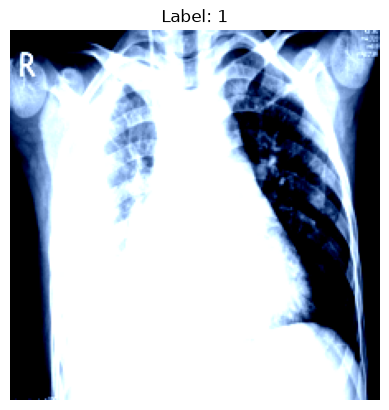

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0322802..1.9428324].


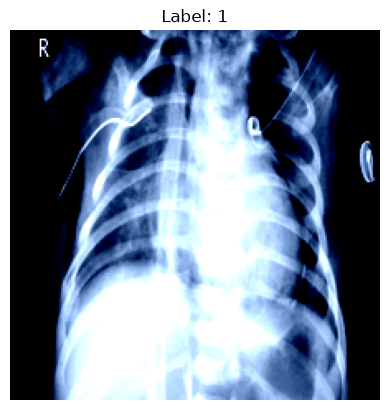

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.4482791].


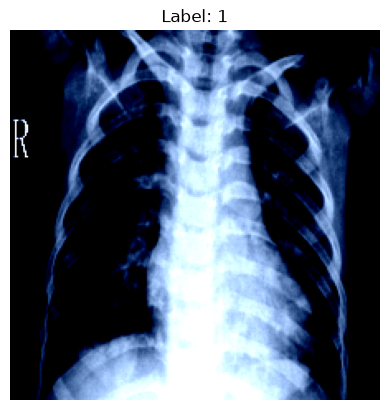

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.535425].


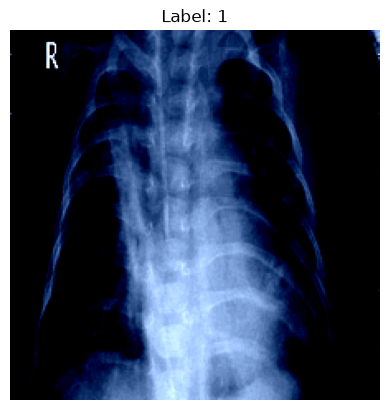

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8781574..2.3785625].


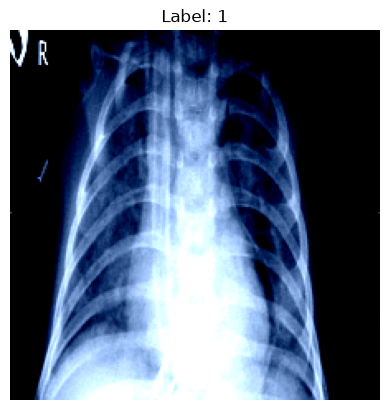

In [14]:
data_iter = iter(train_loader)
batch = next(data_iter)
images, labels = batch
print(f'Images dtypes: {images.dtype}, Images shape: {images.shape}')
print(f'Labels dtypes: {labels.dtype}, Labels shape: {labels.shape}')
print(f'Batch size: {images.size(0)}')
print(f'Number of channels: {images.size(1)}, Image height: {images.size(2)}, Image width: {images.size(3)}')
print(f'Min pixel value: {images.min()}, Max pixel value: {images.max()}')
print(f'Mean pixel value: {images.mean()}, Std pixel value: {images.std()}')
print(f'Unique labels: {labels.unique()}')
print(f'Number of unique labels: {labels.unique().numel()}')

for i, img in enumerate(images[:5]):
    plt.imshow(img.permute(1, 2, 0))  # Convert from CxHxW to HxWxC for visualization
    plt.axis('off')
    plt.title(f'Label: {labels[i]}')
    plt.show()


#### Model Definition

In [15]:
model = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

#### Freeze layers

In [16]:
for param in model.parameters():
    param.requires_grad = False

In [17]:
num__in_features_fc = model.fc.in_features
num_classes = 2  # Example: for binary classification
model.fc = torch.nn.Linear(num__in_features_fc, num_classes)
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [18]:
trainable_params = [param for param in model.parameters() if param.requires_grad]
optimizer = torch.optim.Adam(trainable_params, lr=0.001)
class_weights = torch.tensor([1.9441, 0.6731])
criterion = torch.nn.CrossEntropyLoss(weight=class_weights)

In [19]:
def train(model, train_loader, val_loader, epochs, lr, optimizer, criterion, modelfile, patience=5):

    seed_everything(42)
    train_losses = []
    val_losses = []
    best_loss = float('inf')
    patience_counter = 0

    model.eval()
    for epoch in range(epochs):
        train_running_loss = 0.0
        for image, label in train_loader:
            model.fc.train()
            optimizer.zero_grad()
            output = model(image)
            loss = criterion(output, label)
            loss.backward()
            optimizer.step()
            train_running_loss += loss.item()
        train_losses.append(train_running_loss / len(train_loader))
        val_running_loss = 0.0
        model.eval()
        with torch.no_grad():
            for image, label in val_loader:
                output = model(image)
                loss = criterion(output, label)
                val_running_loss += loss.item()
            val_losses.append(val_running_loss/len(val_loader))
        if val_losses[-1] < best_loss:
            patience_counter = 0
            best_loss = val_losses[-1]
            torch.save(model.state_dict(), modelfile)
        else:
            patience_counter += 1
        if patience_counter >= patience:
            print("Early stopping triggered")
            break
        print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_losses[-1]:.4f}, Val Loss: {val_losses[-1]:.4f}")

In [20]:
def evaluate(model, dataloader, criterion):
    model.eval()
    running_loss = 0.0
    ypreds = []
    ytrues = []
    probs = []
    with torch.no_grad():
        for timg, tlabl in dataloader:
            pred = model(timg)
            prob = torch.softmax(pred, dim=1)
            probs.append(prob)
            loss = criterion(pred, tlabl)
            running_loss += loss.item()
            ypreds.append(pred)
            ytrues.append(tlabl)
    return running_loss/len(dataloader), ypreds, ytrues, probs

#### weighted loss

In [ ]:

seed_everything(42)
model = torchvision.models.resnet18(weights='IMAGENET1K_V1')
for param in model.parameters():
    param.requires_grad = False

model.fc = torch.nn.Linear(model.fc.in_features, num_classes)

trainable_params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(trainable_params, lr=1e-4)
class_weights = torch.tensor([1.9441, 0.6731])
criterion = torch.nn.CrossEntropyLoss(weight=class_weights)

train(model, train_loader, val_loader, epochs=10, lr=1e-4, optimizer=optimizer, criterion=criterion, modelfile='best_classifier_weighted.pth')


✅ Environment successfully seeded with seed: 42
✅ Environment successfully seeded with seed: 42
Epoch 1/10, Train Loss: 0.4220, Val Loss: 0.3351
Epoch 2/10, Train Loss: 0.2813, Val Loss: 0.2567
Epoch 3/10, Train Loss: 0.2262, Val Loss: 0.2210
Epoch 4/10, Train Loss: 0.1988, Val Loss: 0.2016
Epoch 5/10, Train Loss: 0.1827, Val Loss: 0.1885
Epoch 6/10, Train Loss: 0.1726, Val Loss: 0.1732
Epoch 7/10, Train Loss: 0.1620, Val Loss: 0.1653


#### unweighted loss

In [ ]:
model = torchvision.models.resnet18(weights='IMAGENET1K_V1')

for param in model.parameters():
    param.requires_grad = False
model.fc = torch.nn.Linear(model.fc.in_features, 2)

optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-4)
criterion = torch.nn.CrossEntropyLoss()
train(model, train_loader, val_loader, epochs=10, lr=1e-4, optimizer=optimizer, criterion=criterion, modelfile='best_classifier_unweighted.pth')


Epoch 1/10, Train Loss: 0.6370, Val Loss: 0.4549
Epoch 2/10, Train Loss: 0.3744, Val Loss: 0.3351
Epoch 3/10, Train Loss: 0.2835, Val Loss: 0.2694
Epoch 4/10, Train Loss: 0.2333, Val Loss: 0.2311
Epoch 5/10, Train Loss: 0.2033, Val Loss: 0.2072
Epoch 6/10, Train Loss: 0.1837, Val Loss: 0.1893
Epoch 7/10, Train Loss: 0.1700, Val Loss: 0.1767
Epoch 8/10, Train Loss: 0.1590, Val Loss: 0.1672
Epoch 9/10, Train Loss: 0.1512, Val Loss: 0.1585
Epoch 10/10, Train Loss: 0.1455, Val Loss: 0.1514


In [119]:
weighted_model = torchvision.models.resnet18(weights='IMAGENET1K_V1')
weighted_model.fc = torch.nn.Linear(weighted_model.fc.in_features, 2)
state_dict = torch.load("best_classifier_weighted.pth")
weighted_model.load_state_dict(state_dict)


unweighted_model = torchvision.models.resnet18(weights='IMAGENET1K_V1')
unweighted_model.fc = torch.nn.Linear(unweighted_model.fc.in_features, 2)
state_dict_unweighted = torch.load("best_classifier_unweighted.pth")
unweighted_model.load_state_dict(state_dict_unweighted)

<All keys matched successfully>

In [120]:
test_loss, ypreds, ytrues, probs = evaluate(weighted_model, val_loader, criterion)
ypreds = torch.cat(ypreds).argmax(dim=1)
ytrues = torch.cat(ytrues)
probs = torch.cat(probs)

report = classification_report(ytrues, ypreds, target_names=train_original.classes)
print(report)

auc = roc_auc_score(ytrues, probs[:, 1])
print("ROC AUC Score:", auc)

conf_matrix = confusion_matrix(ytrues, ypreds)
print("Confusion Matrix:")
print(conf_matrix)


              precision    recall  f1-score   support

      NORMAL       0.84      0.95      0.89       276
   PNEUMONIA       0.98      0.94      0.96       784

    accuracy                           0.94      1060
   macro avg       0.91      0.94      0.92      1060
weighted avg       0.94      0.94      0.94      1060

ROC AUC Score: 0.9902026027802425
Confusion Matrix:
[[261  15]
 [ 50 734]]


In [121]:
test_loss, ypreds, ytrues, probs = evaluate(unweighted_model, val_loader, criterion)
ypreds = torch.cat(ypreds).argmax(dim=1)
ytrues = torch.cat(ytrues)
probs = torch.cat(probs)

report = classification_report(ytrues, ypreds, target_names=train_original.classes)
print(report)

auc = roc_auc_score(ytrues, probs[:, 1])
print("ROC AUC Score:", auc)

conf_matrix = confusion_matrix(ytrues, ypreds)
print("Confusion Matrix:")
print(conf_matrix)


              precision    recall  f1-score   support

      NORMAL       0.93      0.88      0.90       276
   PNEUMONIA       0.96      0.98      0.97       784

    accuracy                           0.95      1060
   macro avg       0.95      0.93      0.94      1060
weighted avg       0.95      0.95      0.95      1060

ROC AUC Score: 0.9872541407867494
Confusion Matrix:
[[242  34]
 [ 17 767]]


In [125]:
diff_idx = [i for i in range(len(ypreds)) if ypreds[i] != ytrues[i]]
len(diff_idx)

51

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.465708].


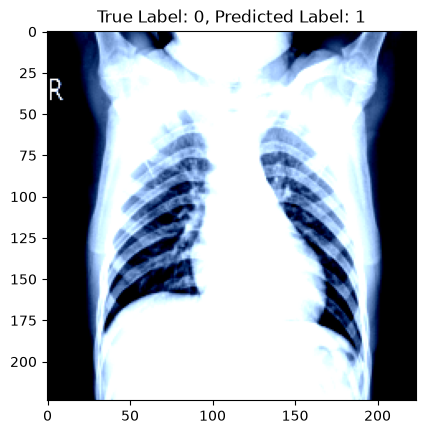

In [129]:
img, lbl = val_dataset[diff_idx[0]]
plt.imshow(img.permute(1, 2, 0))
plt.title(f"True Label: {lbl}, Predicted Label: {ypreds[diff_idx[3]]}")
plt.show()